In [1]:
%pip install -U "qiskit[visualization]" qiskit-ibm-runtime

Note: you may need to restart the kernel to use updated packages.


In [2]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Enter your IBM Quantum CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Connected to IBM Quantum successfully.")

Enter your IBM Quantum API key:  ········
Enter your IBM Quantum CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/4db3032ff9574ab8b189d65aca927eb7:afda762a-3892-48ce-beff-b56cb09b4f57::


qiskit_runtime_service._discover_account:WARNING:2026-10-11 22:54:28,237: Loading account with the given token. A saved account will not be used.


Connected to IBM Quantum successfully.


In [3]:
backend = service.least_busy(
    min_num_qubits=2,
    operational=True,
    simulator=False
)

print("Selected backend:", backend.name)
print("Backend status:", backend.status().status_msg)

Selected backend: ibm_fez
Backend status: active


Qiskit Fall Fest 2026

Challenge 3: Can You Change the Correlation?

Prediction

The original Bell-state circuit is expected to produce the outcomes 00 and 11.

In the modified circuit, one X gate is added to the second qubit. I predict that the outcomes will change to 01 and 10.

Both circuits will be executed for 100 shots on IBM Quantum hardware. The measurement counts and histograms will be compared.

Original Bell-state circuit


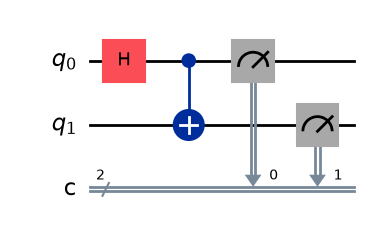

Modified Bell-state circuit


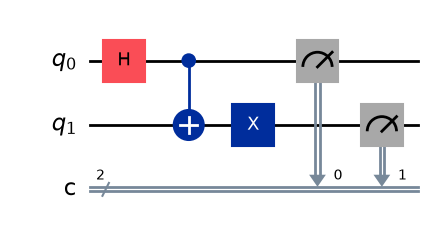

In [4]:
# CELL 5: Create the Bell-state circuits

from qiskit import QuantumCircuit
from IPython.display import display

# Original Bell-state circuit
original_circuit = QuantumCircuit(2, 2)
original_circuit.h(0)
original_circuit.cx(0, 1)
original_circuit.measure([0, 1], [0, 1])

# Modified circuit: Add one X gate to qubit 1
modified_circuit = QuantumCircuit(2, 2)
modified_circuit.h(0)
modified_circuit.cx(0, 1)
modified_circuit.x(1)
modified_circuit.measure([0, 1], [0, 1])

circuits = [original_circuit, modified_circuit]

print("Original Bell-state circuit")
display(original_circuit.draw("mpl"))

print("Modified Bell-state circuit")
display(modified_circuit.draw("mpl"))

In [5]:
# CELL 6: Compile circuits for IBM hardware

from qiskit.transpiler import generate_preset_pass_manager

pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

compiled_circuits = pass_manager.run(circuits)

print("Both circuits are ready for hardware execution.")

Both circuits are ready for hardware execution.


In [6]:
# CELL 7: Execute both circuits on IBM Quantum

from qiskit_ibm_runtime import SamplerV2

sampler = SamplerV2(mode=backend)

job = sampler.run(
    compiled_circuits,
    shots=100
)

print("Job ID:", job.job_id())
print("Waiting for results...")

result = job.result()

print("Hardware execution completed.")

C:\Users\SUSEELA\AppData\Local\Temp\ipykernel_18640\369776628.py:5: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job ID: db5sdpcvf2bc73d0bon0
Waiting for results...
Hardware execution completed.


In [7]:
# CELL 8: Extract measurement counts

print("Available result fields:", result[0].data.keys())

counts_original = result[0].data.c.get_counts()
counts_modified = result[1].data.c.get_counts()

print("Original circuit counts:", counts_original)
print("Original total shots:", sum(counts_original.values()))

print()

print("Modified circuit counts:", counts_modified)
print("Modified total shots:", sum(counts_modified.values()))

Available result fields: dict_keys(['c'])
Original circuit counts: {'00': 43, '11': 53, '10': 3, '01': 1}
Original total shots: 100

Modified circuit counts: {'01': 45, '10': 46, '00': 6, '11': 3}
Modified total shots: 100


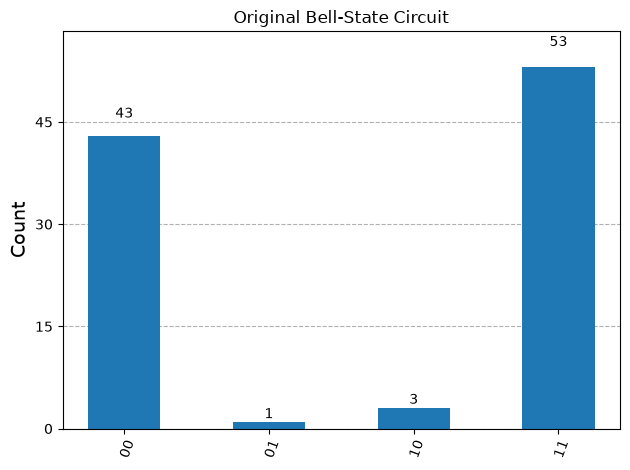

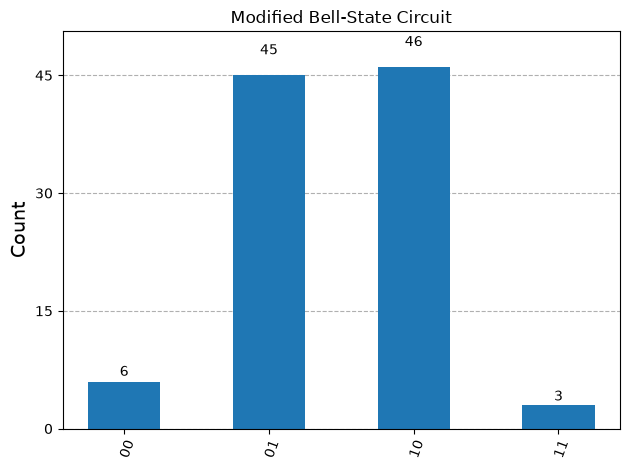

In [8]:
# CELL 9: Plot the measurement results

from qiskit.visualization import plot_histogram

display(plot_histogram(
    counts_original,
    title="Original Bell-State Circuit"
))

display(plot_histogram(
    counts_modified,
    title="Modified Bell-State Circuit"
))

In [9]:
# CELL 10: Compare original and modified circuits

import pandas as pd

comparison = pd.DataFrame([
    {
        "Circuit": "Original Bell State",
        "Expected Outcomes": "00 and 11",
        "Actual Counts": str(counts_original),
        "Total Shots": sum(counts_original.values())
    },
    {
        "Circuit": "Modified Bell State",
        "Expected Outcomes": "01 and 10",
        "Actual Counts": str(counts_modified),
        "Total Shots": sum(counts_modified.values())
    }
])

display(comparison)

,Circuit,Expected Outcomes,Actual Counts,Total Shots
0,Original Bell State,00 and 11,"{'00': 43, '11': 53, '10': 3, '01': 1}",100
1,Modified Bell State,01 and 10,"{'01': 45, '10': 46, '00': 6, '11': 3}",100


Observation and Conclusion

The original Bell-state circuit was expected to produce the outcomes 00 and 11, showing correlated measurement results.

After adding an X gate to the second qubit, the modified circuit was expected to produce the outcomes 01 and 10. The two qubits therefore produce opposite measurement values.

The results show that adding a single quantum gate can change the relationship between the measurement outcomes. Small deviations from the expected results may occur because of statistical fluctuations and noise in real quantum hardware.